# Monte Carlo methods

Numerical Methods group project, iMAT, ICAI, Universidad Pontificia Comillas,
2025–2026. Academic context is in [README.md](README.md).

Exercises 1–24 explore uniform integration, hit-or-miss and importance sampling,
rectangular and circular domains, and tensor-grid cost in higher dimensions.
Saved outputs use the reduced run described in the README.
[Technical notes](docs/technical-notes.md) explain execution settings and
mathematical limits. This version includes the post-submission corrections
summarised in the README.


## Setup and reproducibility

Run all cells in order. The default seed is 20261017. The default cap of
50,000 samples keeps every section practical; repeated studies use up to
30 independent estimates. These settings deliberately differ from the large
historical runs. Set `MC_MAX_SAMPLES`, `MC_REPEATS` and `MC_SEED` before running
to change them. `results/` receives figures and a machine-written summary.
Timing measurements are hardware-dependent; numerical results also depend
on the random generator, NumPy/SciPy versions and the full execution order.


In [1]:
import json
import os
import platform
import time
from pathlib import Path

import numpy as np
import scipy
import matplotlib
from matplotlib import pyplot as plt
from scipy.special import erf
from scipy.integrate import quad, dblquad
from scipy.stats import norm

SEED = int(os.environ.get('MC_SEED', '20261017'))
MAX_SAMPLES = int(os.environ.get('MC_MAX_SAMPLES', '50000'))
REPEATS = int(os.environ.get('MC_REPEATS', '30'))
if MAX_SAMPLES < 100 or REPEATS < 2:
    raise ValueError('Use at least 100 samples and two repeats.')
np.random.seed(SEED)
RESULTS = Path(os.environ.get('MC_RESULTS_DIR', 'results'))
RESULTS.mkdir(parents=True, exist_ok=True)

def sample_count(requested):
    return min(requested, MAX_SAMPLES)

def sample_sizes(max_power=6):
    return sorted({min(m * 10**power, MAX_SAMPLES)
                   for power in range(1, max_power + 1) for m in (1, 5)})

def save_figure(name):
    plt.savefig(RESULTS / name, dpi=140, bbox_inches='tight')
    plt.show()
    plt.close()

print(f'Seed: {SEED}; sample cap: {MAX_SAMPLES}; repeat cap: {REPEATS}')
print(f'Python {platform.python_version()}, NumPy {np.__version__}, SciPy {scipy.__version__}')


Seed: 20261017; sample cap: 50000; repeat cap: 30
Python 3.12.14, NumPy 2.5.4, SciPy 1.18.1


## 1. Uniform Monte Carlo integration — exercises 1–2

For independent uniform samples on $[a,b]$,
$$\widehat I=(b-a)\frac1n\sum_{i=1}^n f(X_i),\qquad X_i\sim U(a,b).$$
The estimator is unbiased when the integral exists. Its standard error is
$(b-a)\sqrt{\operatorname{Var}(f(X))/n}$ when the variance is finite.
The examples below have known analytical integrals.


In [2]:
def uniform_integral(f, a, b, n):
    """Integrate a vectorised function using n independent uniform samples."""
    if n <= 0 or b <= a:
        raise ValueError('Require n > 0 and b > a.')
    step = (b - a) / n
    samples = np.random.uniform(a, b, n)
    return step * np.sum(f(samples))

functions = [
    (lambda x: x**2, 0, 1, 1/3, 'x²'),
    (np.sin, 0, np.pi, 2.0, 'sin(x)'),
    (np.exp, 0, 1, np.e - 1, 'exp(x)'),
]
for f, a, b, exact, name in functions:
    estimate = uniform_integral(f, a, b, sample_count(10000))
    print(f'Integral of {name}: estimate={estimate:.6f}, exact={exact:.6f}, absolute error={abs(estimate-exact):.6f}')


Integral of x²: estimate=0.329919, exact=0.333333, absolute error=0.003414
Integral of sin(x): estimate=1.992425, exact=2.000000, absolute error=0.007575
Integral of exp(x): estimate=1.715980, exact=1.718282, absolute error=0.002302


## 2. Repeated estimates — exercise 3

Independent repeats reveal sampling variation. The sample variance uses
`ddof=1`; it measures variation between whole integral estimates.


In [3]:
def repeat_integral(f, a, b, n, repeats):
    return [uniform_integral(f, a, b, n) for _ in range(repeats)]

def sample_statistics(results):
    if len(results) < 2:
        raise ValueError('Sample variance requires at least two estimates.')
    return np.mean(results), np.var(results, ddof=1)

f = lambda x: x**2
a3, b3 = 0, 1
repeats3 = min(10, REPEATS)
results = repeat_integral(f, a3, b3, sample_count(10000), repeats3)
mean, variance = sample_statistics(results)
for index, estimate in enumerate(results, 1):
    print(f'Run {index}: {estimate:.8f}')
print(f'Mean={mean:.8f}; sample variance={variance:.8g}')


Run 1: 0.33147128
Run 2: 0.33237149
Run 3: 0.32887814
Run 4: 0.33304792
Run 5: 0.33229292
Run 6: 0.33630234
Run 7: 0.33287057
Run 8: 0.33413177
Run 9: 0.33535480
Run 10: 0.34155417
Mean=0.33382754; sample variance=1.1588639e-05


## 3. Sample size and variance — exercises 4–5

The predicted variance decreases as $1/n$. A finite set of runs need not
show a strictly monotone decrease, and the standard error is not a bound on
the realised absolute error.


In [4]:
for n_test in sorted({sample_count(n) for n in [100, 1000, 10000, 100000]}):
    estimates = repeat_integral(f, a3, b3, n_test, min(50, REPEATS))
    mean, variance = sample_statistics(estimates)
    print(f'n={n_test}: mean={mean:.6f}, sample variance={variance:.8g}')


n=100: mean=0.332545, sample variance=0.0014296372
n=1000: mean=0.333419, sample variance=0.00011751346
n=10000: mean=0.333546, sample variance=1.5531334e-05
n=50000: mean=0.333435, sample variance=1.610756e-06


## 4. Estimating π by integration — exercise 6

Use $\pi=\int_0^1 4\sqrt{1-x^2}\,dx$. Here the reported error belongs to
the **mean of repeated estimates**, rather than to a single estimate.
Exercise 8 below instead studies the mean absolute error of individual runs.


In [5]:
f6 = lambda x: 4 * np.sqrt(1 - x**2)
a6, b6 = 0, 1
exact6 = np.pi
sizes = sample_sizes()
estimates6, errors6 = [], []
for n in sizes:
    estimates = repeat_integral(f6, a6, b6, n, REPEATS)
    mean = np.mean(estimates)
    error = abs(mean - exact6)
    estimates6.append(mean)
    errors6.append(error)
    print(f'n={n}: mean estimate={mean:.8f}, absolute error of mean={error:.6g}, relative error={error/exact6:.6g}')


n=10: mean estimate=3.15847663, absolute error of mean=0.016884, relative error=0.00537434
n=50: mean estimate=3.17991802, absolute error of mean=0.0383254, relative error=0.0121993
n=100: mean estimate=3.12834725, absolute error of mean=0.0132454, relative error=0.00421614
n=500: mean estimate=3.13845905, absolute error of mean=0.00313361, relative error=0.000997459
n=1000: mean estimate=3.13538316, absolute error of mean=0.0062095, relative error=0.00197654
n=5000: mean estimate=3.14025906, absolute error of mean=0.00133359, relative error=0.000424495
n=10000: mean estimate=3.14236339, absolute error of mean=0.000770739, relative error=0.000245334
n=50000: mean estimate=3.14104371, absolute error of mean=0.000548946, relative error=0.000174735


## 5. Error plot — exercise 7

The $n^{-1/2}$ line is a visual reference, scaled to the first observation.
With a fixed repeat count the standard error of the average still scales
as $n^{-1/2}$, but its constant differs from that of one run.


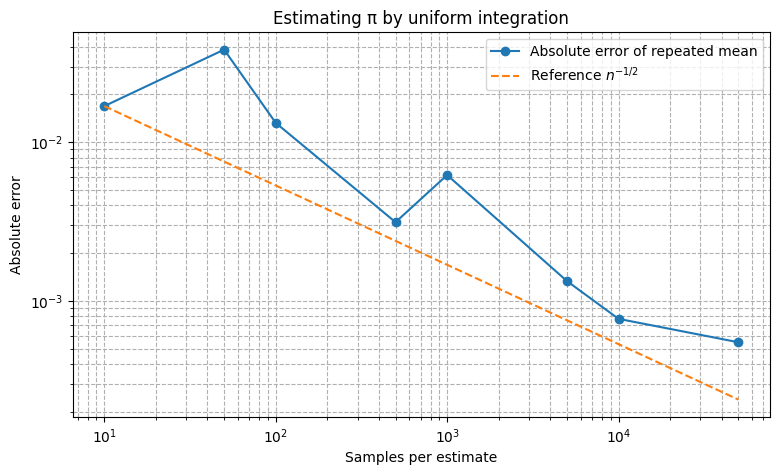

In [6]:
def plot_errors(sizes, errors):
    reference = [errors[0] * (sizes[0]/n)**0.5 for n in sizes]
    plt.figure(figsize=(9, 5))
    plt.loglog(sizes, errors, 'o-', label='Absolute error of repeated mean')
    plt.loglog(sizes, reference, '--', label=r'Reference $n^{-1/2}$')
    plt.xlabel('Samples per estimate')
    plt.ylabel('Absolute error')
    plt.title('Estimating π by uniform integration')
    plt.legend()
    plt.grid(True, which='both', ls='--')
    save_figure('pi-convergence.png')

plot_errors(sizes, errors6)


## 6. Empirical convergence slope — exercise 8

Average the absolute errors of independent estimates at each sample size.
Adjacent log–log slopes are noisy empirical comparisons, not a proof that
every run has error $n^{-1/2}$. The theoretical exponent refers to standard
error with finite variance; the mean absolute error often exhibits the same
asymptotic scaling under the usual central-limit behaviour.


In [7]:
errors8 = []
for n in sizes:
    estimates = repeat_integral(f6, a6, b6, n, REPEATS)
    errors8.append(np.mean([abs(value - exact6) for value in estimates]))
slopes = np.diff(np.log(errors8)) / np.diff(np.log(sizes))
print(f'Adjacent log-log slopes: {np.round(slopes, 3).tolist()}')
print(f'Mean adjacent slope: {np.mean(slopes):.3f}; reference exponent: -0.500')


Adjacent log-log slopes: [-0.437, -0.353, -0.596, -0.236, -0.686, -0.473, -0.26]
Mean adjacent slope: -0.435; reference exponent: -0.500


## 7. Hit-or-miss integration — exercises 9–11

Sample the enclosing rectangle $[a,b]\times[0,M]$ and count points under the
curve. This estimator requires $0\leq f(x)\leq M$ throughout the interval:
$$\widehat I=(b-a)M\,\frac{\#\{Y_i\leq f(X_i)\}}n.$$
It does not handle signed integrands without an additional transformation.


In [8]:
def random_rectangle_points(a, b, height, n):
    if n <= 0 or b <= a or height <= 0:
        raise ValueError('Require n > 0, b > a and height > 0.')
    x = np.random.uniform(a, b, n)
    y = np.random.uniform(0, height, n)
    return np.column_stack((x, y))

def points_under_curve(f, points):
    x, y = points[:, 0], points[:, 1]
    return points[y <= f(x)]

def hit_fraction(f, a, b, height, n):
    points = random_rectangle_points(a, b, height, n)
    x, y = points[:, 0], points[:, 1]
    return np.sum(y <= f(x)) / n

def hit_or_miss_integral(f, a, b, height, n):
    """The caller must supply an upper bound height for a non-negative f."""
    return hit_fraction(f, a, b, height, n) * (b - a) * height

functions11 = [
    (lambda x: x**2, 0, 1, 1, 1/3, 'x²'),
    (np.sin, 0, np.pi, 1, 2.0, 'sin(x)'),
    (np.exp, 0, 1, np.e, np.e-1, 'exp(x)'),
]
for f, a, b, height, exact, name in functions11:
    estimate = hit_or_miss_integral(f, a, b, height, sample_count(100000))
    print(f'{name}: estimate={estimate:.6f}, exact={exact:.6f}, error={abs(estimate-exact):.6f}')


x²: estimate=0.333320, exact=0.333333, error=0.000013
sin(x): estimate=1.999247, exact=2.000000, error=0.000753
exp(x): estimate=1.723554, exact=1.718282, error=0.005272


## 8. A narrow Gaussian peak — exercise 12

For $f(x)=\exp(-x^2/(2\sigma^2))$ on $[-1,1]$ with $\sigma=0.05$, the exact
integral is $\sigma\sqrt{2\pi}\,\operatorname{erf}(1/(\sigma\sqrt2))$.
The whole-real-line integral omits the error-function factor; here the
numerical difference is negligible because the excluded tails are tiny.


In [9]:
sigma = 0.05
f12 = lambda x: np.exp(-x**2 / (2 * sigma**2))
a12, b12, height12 = -1, 1, 1
exact12 = sigma * np.sqrt(2*np.pi) * erf(1/(sigma*np.sqrt(2)))
n12 = sample_count(10000)
estimate12 = uniform_integral(f12, a12, b12, n12)
print(f'Uniform estimate={estimate12:.6f}; exact integral on [-1,1]={exact12:.6f}')
print(f'Whole-real-line integral={sigma*np.sqrt(2*np.pi):.6f}')


Uniform estimate=0.122248; exact integral on [-1,1]=0.125331
Whole-real-line integral=0.125331


## 9. Seeing the sampled points — exercise 13

Most uniform points in the enclosing rectangle miss the narrow peak.
This is a geometric illustration; the fraction of accepted points and the
variance of the uniform integral estimator are different quantities.


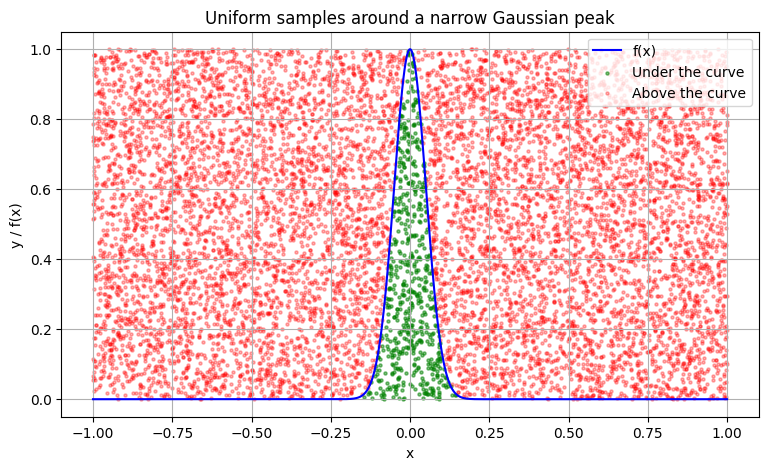

In [10]:
x_plot = np.linspace(a12, b12, 1000)
x_samples = np.random.uniform(a12, b12, n12)
y_samples = np.random.uniform(0, height12, n12)
under_curve = y_samples <= f12(x_samples)
plt.figure(figsize=(9, 5))
plt.plot(x_plot, f12(x_plot), 'b-', label='f(x)')
plt.scatter(x_samples[under_curve], y_samples[under_curve], alpha=0.5, s=5, color='green', label='Under the curve')
plt.scatter(x_samples[~under_curve], y_samples[~under_curve], alpha=0.3, s=5, color='red', label='Above the curve')
plt.xlabel('x')
plt.ylabel('y / f(x)')
plt.title('Uniform samples around a narrow Gaussian peak')
plt.legend()
plt.grid(True)
save_figure('narrow-peak-sampling.png')


## 10. Narrow-peak convergence — exercise 14

Report both the mean estimate and the mean absolute error. Averaging signed
errors would allow cancellation and would not measure typical error.


n=     10: mean=0.152150; mean absolute error=0.117370
n=     50: mean=0.129967; mean absolute error=0.043556
n=    100: mean=0.130534; mean absolute error=0.030786
n=    500: mean=0.128851; mean absolute error=0.010951
n=   1000: mean=0.125558; mean absolute error=0.013546
n=   5000: mean=0.126379; mean absolute error=0.004181
n=  10000: mean=0.124950; mean absolute error=0.002865
n=  50000: mean=0.124933; mean absolute error=0.001586


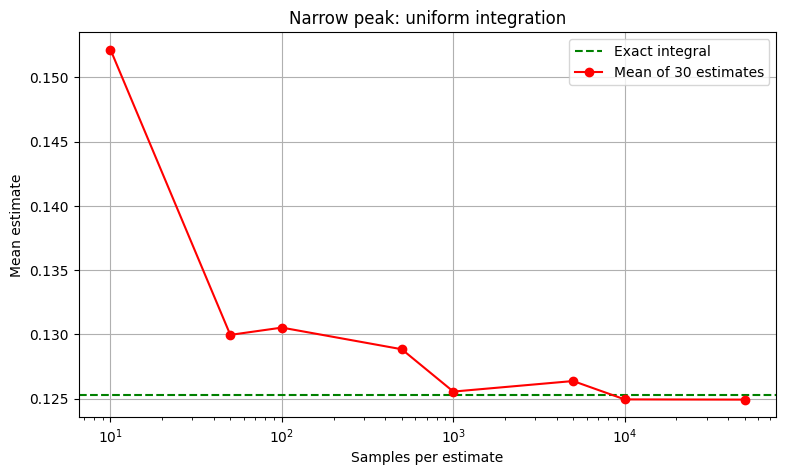

In [11]:
sizes14 = sample_sizes()
mean_errors14, mean_estimates14 = [], []
for n in sizes14:
    estimates = repeat_integral(f12, a12, b12, n, REPEATS)
    mean = np.mean(estimates)
    mean_error = np.mean([abs(value-exact12) for value in estimates])
    mean_estimates14.append(mean)
    mean_errors14.append(mean_error)
    print(f'n={n:7d}: mean={mean:.6f}; mean absolute error={mean_error:.6f}')
plt.figure(figsize=(9, 5))
plt.axhline(exact12, color='green', ls='--', label='Exact integral')
plt.semilogx(sizes14, mean_estimates14, 'o-', color='red', label=f'Mean of {REPEATS} estimates')
plt.xlabel('Samples per estimate')
plt.ylabel('Mean estimate')
plt.title('Narrow peak: uniform integration')
plt.legend()
plt.grid(True)
save_figure('narrow-peak-convergence.png')


## 11. Importance sampling — exercise 15

For samples drawn from a **normalised** density $\rho$,
$$\int f(x)\,dx=E_\rho[f(X)/\rho(X)].$$
The proposal must cover the support where the integrand is non-zero.
Finite standard error additionally requires a finite second moment of the
weights. A poorly matched proposal can increase variance. These conditions
are the caller's responsibility; checking sampled densities alone cannot
prove support coverage. The first example uses $\rho(x)=2x$ on $[0,1]$.


In [12]:
def importance_sampling(f, density, sample_generator, n):
    """Estimate an integral using samples and their matching normalised density."""
    if n <= 0:
        raise ValueError('Require n > 0.')
    samples = sample_generator(n)
    probabilities = density(samples)
    if np.any(~np.isfinite(probabilities)) or np.any(probabilities <= 0):
        raise ValueError('The sampled proposal density must be finite and positive.')
    return np.mean(f(samples) / probabilities)

f_test = lambda x: x**2
density_test = lambda x: 2*x
generate_test = lambda n: np.sqrt(np.random.uniform(0, 1, n))
estimate_is = importance_sampling(f_test, density_test, generate_test, sample_count(100000))
print(f'Integral of x² on [0,1]: importance estimate={estimate_is:.6f}; exact={1/3:.6f}')


Integral of x² on [0,1]: importance estimate=0.333333; exact=0.333333


## 12. Importance sampling of the narrow peak — exercise 16

Use the original rejection sampler for a Gaussian truncated to $[-1,1]$.
Its density is proportional to the integrand, so $f(x)/\rho(x)=Z$ is constant.
The resulting zero theoretical variance is an **ideal explanatory case**:
knowing the normalising constant $Z$ already provides this integral. It is
not a general free solution to integration. Floating-point round-off may
produce tiny non-zero errors; exact zeros are omitted from the log plot.


Samples | Uniform mean absolute error | Importance mean absolute error
     10 | 0.11413908 | 0
     50 | 0.044487129 | 0
    100 | 0.023219616 | 2.7755576e-17
    500 | 0.010937353 | 2.7755576e-17
   1000 | 0.011131617 | 0
   5000 | 0.0038513728 | 2.7755576e-17
  10000 | 0.0027110157 | 2.7755576e-17
  50000 | 0.001574761 | 2.7755576e-17


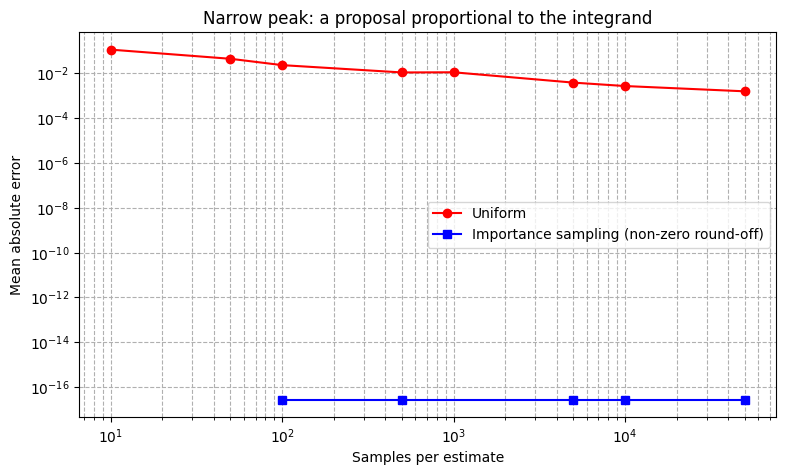

In [13]:
sigma_is = 0.05
normalising_constant = sigma_is*np.sqrt(2*np.pi)*erf(1/(sigma_is*np.sqrt(2)))
gaussian_density = lambda x: np.exp(-x**2/(2*sigma_is**2))/normalising_constant

def truncated_gaussian_samples(n):
    samples = []
    while len(samples) < n:
        candidates = np.random.normal(0, sigma_is, n-len(samples)+1000)
        accepted = candidates[(candidates >= a12) & (candidates <= b12)]
        samples.extend(accepted.tolist())
    return np.array(samples[:n])

sizes16 = sample_sizes(5)
uniform_errors, importance_errors = [], []
print('Samples | Uniform mean absolute error | Importance mean absolute error')
for n in sizes16:
    uniform_results = repeat_integral(f12, a12, b12, n, REPEATS)
    importance_results = [importance_sampling(f12, gaussian_density, truncated_gaussian_samples, n) for _ in range(REPEATS)]
    uniform_error = np.mean([abs(value-exact12) for value in uniform_results])
    importance_error = np.mean([abs(value-exact12) for value in importance_results])
    uniform_errors.append(uniform_error)
    importance_errors.append(importance_error)
    print(f'{n:7d} | {uniform_error:.8g} | {importance_error:.8g}')
plt.figure(figsize=(9, 5))
plt.loglog(sizes16, uniform_errors, 'o-', color='red', label='Uniform')
positive_errors = np.array(importance_errors) > 0
if np.any(positive_errors):
    plt.loglog(np.array(sizes16)[positive_errors], np.array(importance_errors)[positive_errors], 's-', color='blue', label='Importance sampling (non-zero round-off)')
plt.xlabel('Samples per estimate')
plt.ylabel('Mean absolute error')
plt.title('Narrow peak: a proposal proportional to the integrand')
plt.legend()
plt.grid(True, which='both', ls='--')
save_figure('importance-narrow-peak.png')


## 13. Choosing a Gaussian proposal — exercise 17

Compare uniform sampling with truncated Gaussian proposals for
$f(x)=1/(1+x^6)$ on $[-3,3]$. The five proposal variances are those in the
submitted notebook. `quad` supplies a numerical reference, not an exact
symbolic value. Very narrow proposals can produce rare large weights;
30 repeats are not enough to exclude that risk.


Quadrature reference=2.09275004; reported integration error=4.7e-12
Uniform mean absolute error (30 runs, n=50000): 0.008257
Variance=0.25; mean=2.093459; mean absolute error=0.008924
Variance=1.00; mean=2.092742; mean absolute error=0.003167
Variance=2.25; mean=2.093333; mean absolute error=0.006949
Variance=4.00; mean=2.091953; mean absolute error=0.006495
Variance=9.00; mean=2.091578; mean absolute error=0.006285


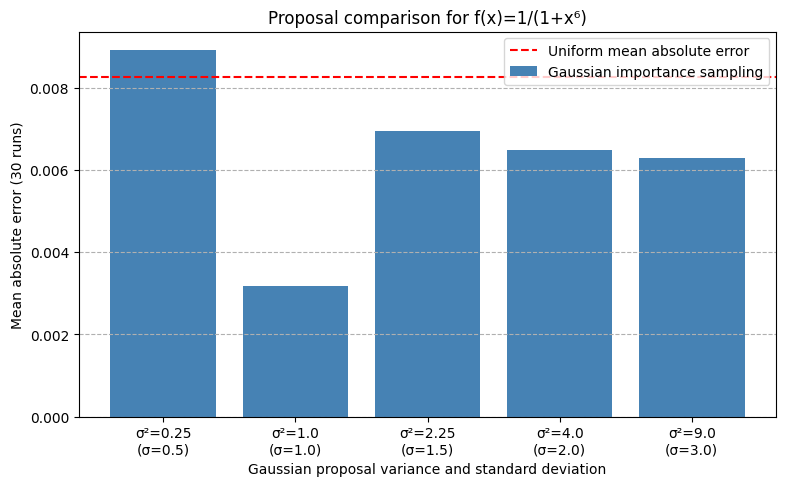

Lowest observed mean absolute error among these proposals: variance=1.0.
This finite experiment does not establish a universally optimal proposal.


In [14]:
f17 = lambda x: 1/(1+x**6)
a17, b17 = -3, 3
reference17, quadrature_error17 = quad(f17, a17, b17)
n17 = sample_count(100000)
uniform_results17 = repeat_integral(f17, a17, b17, n17, REPEATS)
uniform_error17 = np.mean([abs(value-reference17) for value in uniform_results17])
variances17 = [0.25, 1.0, 2.25, 4.0, 9.0]
sigmas17 = [np.sqrt(value) for value in variances17]
proposal_errors = []
print(f'Quadrature reference={reference17:.8f}; reported integration error={quadrature_error17:.2g}')
print(f'Uniform mean absolute error ({REPEATS} runs, n={n17}): {uniform_error17:.6f}')
for variance, sigma_proposal in zip(variances17, sigmas17):
    normaliser = norm.cdf(b17, 0, sigma_proposal)-norm.cdf(a17, 0, sigma_proposal)
    density17 = lambda x, s=sigma_proposal, z=normaliser: norm.pdf(x, 0, s)/z

    def generate_gaussian17(n, s=sigma_proposal):
        samples = []
        while len(samples) < n:
            candidates = np.random.normal(0, s, n-len(samples)+2000)
            accepted = candidates[(candidates >= a17) & (candidates <= b17)]
            samples.extend(accepted.tolist())
        return np.array(samples[:n])

    estimates = [importance_sampling(f17, density17, generate_gaussian17, n17) for _ in range(REPEATS)]
    error = np.mean([abs(value-reference17) for value in estimates])
    proposal_errors.append(error)
    print(f'Variance={variance:.2f}; mean={np.mean(estimates):.6f}; mean absolute error={error:.6f}')
labels = [f'σ²={variance}\n(σ={sigma:.1f})' for variance, sigma in zip(variances17, sigmas17)]
plt.figure(figsize=(9, 5))
plt.bar(labels, proposal_errors, color='steelblue', label='Gaussian importance sampling')
plt.axhline(uniform_error17, color='red', ls='--', label='Uniform mean absolute error')
plt.xlabel('Gaussian proposal variance and standard deviation')
plt.ylabel(f'Mean absolute error ({REPEATS} runs)')
plt.title('Proposal comparison for f(x)=1/(1+x⁶)')
plt.legend()
plt.grid(True, axis='y', ls='--')
save_figure('proposal-comparison.png')
best_variance17 = variances17[int(np.argmin(proposal_errors))]
print(f'Lowest observed mean absolute error among these proposals: variance={best_variance17}.')
print('This finite experiment does not establish a universally optimal proposal.')


## 14. Uniform Monte Carlo and the left-rectangle rule — exercise 18

For this smooth one-dimensional integrand, the composite left-rectangle
rule has error $O(n^{-1})$, while Monte Carlo has standard error
$O(n^{-1/2})$. This comparison does not establish superiority for all
one-dimensional problems or all deterministic integration methods.
The horizontal axis counts evaluations in **one** estimate; repeated Monte
Carlo estimates multiply the total experimental work by the repeat count.


n=     10: MC mean absolute error=0.16487249; rectangle error=0.08448243
n=     50: MC mean absolute error=0.05536768; rectangle error=0.01712554
n=    100: MC mean absolute error=0.03100600; rectangle error=0.00857709
n=    500: MC mean absolute error=0.01982272; rectangle error=0.00171771
n=   1000: MC mean absolute error=0.01166451; rectangle error=0.00085900
n=   5000: MC mean absolute error=0.00582330; rectangle error=0.00017182
n=  10000: MC mean absolute error=0.00408630; rectangle error=0.00008591
n=  50000: MC mean absolute error=0.00161159; rectangle error=0.00001718


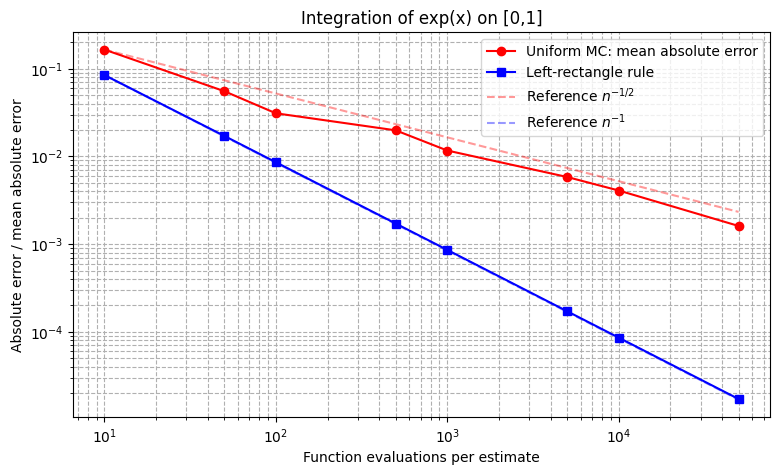

In [15]:
def left_rectangle_rule(f, a, b, n):
    """Use the left endpoint of each of n equally sized subintervals."""
    if n <= 0 or b <= a:
        raise ValueError('Require n > 0 and b > a.')
    step = (b-a)/n
    x = np.linspace(a, a+(n-1)*step, n)
    return step*np.sum(f(x))

f18 = np.exp
exact18 = np.e-1
sizes18 = sample_sizes(5)
mc_errors18, rectangle_errors18 = [], []
for n in sizes18:
    estimates = repeat_integral(f18, 0, 1, n, REPEATS)
    mc_errors18.append(np.mean([abs(value-exact18) for value in estimates]))
    rectangle_errors18.append(abs(left_rectangle_rule(f18, 0, 1, n)-exact18))
    print(f'n={n:7d}: MC mean absolute error={mc_errors18[-1]:.8f}; rectangle error={rectangle_errors18[-1]:.8f}')
plt.figure(figsize=(9, 5))
plt.loglog(sizes18, mc_errors18, 'o-', color='red', label='Uniform MC: mean absolute error')
plt.loglog(sizes18, rectangle_errors18, 's-', color='blue', label='Left-rectangle rule')
plt.loglog(sizes18, [mc_errors18[0]*(sizes18[0]/n)**0.5 for n in sizes18], '--', color='red', alpha=0.4, label=r'Reference $n^{-1/2}$')
plt.loglog(sizes18, [rectangle_errors18[0]*sizes18[0]/n for n in sizes18], '--', color='blue', alpha=0.4, label=r'Reference $n^{-1}$')
plt.xlabel('Function evaluations per estimate')
plt.ylabel('Absolute error / mean absolute error')
plt.title('Integration of exp(x) on [0,1]')
plt.legend()
plt.grid(True, which='both', ls='--')
save_figure('rectangle-comparison.png')


## 15. Two-dimensional integration — exercise 19

Uniform sampling extends to a rectangle $D$:
$$\widehat I=\operatorname{area}(D)\frac1n\sum_i f(X_i,Y_i).$$
The area is known, and the integrand accepts NumPy arrays.


In [16]:
def uniform_integral_2d(f, ax, bx, ay, by, n):
    if n <= 0 or bx <= ax or by <= ay:
        raise ValueError('Require n > 0 and increasing bounds.')
    area = (bx-ax)*(by-ay)
    x = np.random.uniform(ax, bx, n)
    y = np.random.uniform(ay, by, n)
    return area*np.mean(f(x, y))


## 16. Two-dimensional examples — exercise 20

The polynomial and trigonometric examples have analytical integrals. The
Gaussian example uses numerical double quadrature as its reference.


x²+y²: mean=0.666327, reference=0.666667, mean absolute error=0.001790
sin(x)cos(y): mean=1.998880, reference=2.000000, mean absolute error=0.004274
exp(-(x²+y²)): mean=2.230697, reference=2.230985, mean absolute error=0.002670


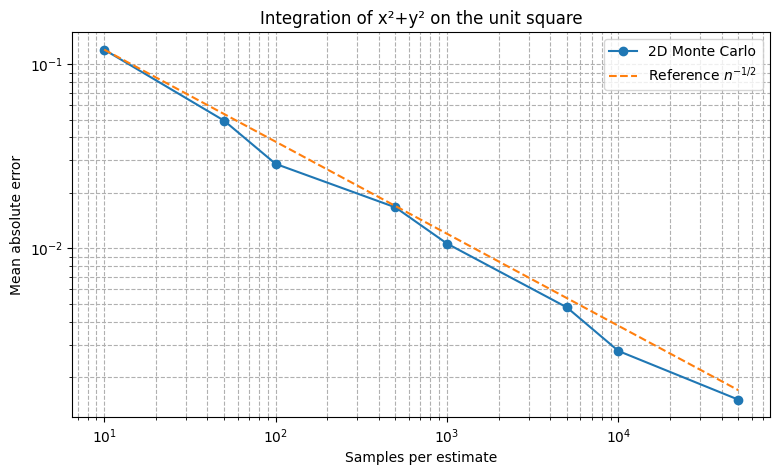

In [17]:
f20a = lambda x, y: x**2+y**2
f20b = lambda x, y: np.sin(x)*np.cos(y)
f20c = lambda x, y: np.exp(-(x**2+y**2))
reference20c, _ = dblquad(lambda y, x: np.exp(-(x**2+y**2)), -1, 1, -1, 1)
functions2d = [
    (f20a, 0, 1, 0, 1, 2/3, 'x²+y²'),
    (f20b, 0, np.pi, 0, np.pi/2, 2.0, 'sin(x)cos(y)'),
    (f20c, -1, 1, -1, 1, reference20c, 'exp(-(x²+y²))'),
]
n20 = sample_count(100000)
for f, ax, bx, ay, by, reference, name in functions2d:
    estimates = [uniform_integral_2d(f, ax, bx, ay, by, n20) for _ in range(REPEATS)]
    error = np.mean([abs(value-reference) for value in estimates])
    print(f'{name}: mean={np.mean(estimates):.6f}, reference={reference:.6f}, mean absolute error={error:.6f}')
sizes20 = sample_sizes(5)
errors2d = []
for n in sizes20:
    estimates = [uniform_integral_2d(f20a, 0, 1, 0, 1, n) for _ in range(REPEATS)]
    errors2d.append(np.mean([abs(value-2/3) for value in estimates]))
plt.figure(figsize=(9, 5))
plt.loglog(sizes20, errors2d, 'o-', label='2D Monte Carlo')
plt.loglog(sizes20, [errors2d[0]*(sizes20[0]/n)**0.5 for n in sizes20], '--', label=r'Reference $n^{-1/2}$')
plt.xlabel('Samples per estimate')
plt.ylabel('Mean absolute error')
plt.title('Integration of x²+y² on the unit square')
plt.legend()
plt.grid(True, which='both', ls='--')
save_figure('two-dimensional-convergence.png')


## 17. Rejection sampling in a disc — exercise 21

Generate candidates in $[-r,r]^2$ and retain those in the disc. Conditional
on acceptance they are uniform in the disc. The integration routine uses
the **known area** $\pi r^2$ times their mean function value. For $f=1$ its
answer is $\pi r^2$ by construction: this is not an independent estimate of π.
If no candidates are accepted the conditional mean is undefined, so the
routine raises an error rather than returning `nan` silently.

A separate **area estimate** uses the square's area times the acceptance
fraction, $4r^2 n_{accepted}/n_{candidates}$. It does not use π in its formula.


f=1 (known-area identity): mean=3.141593; mean absolute error=0.000000
f=x²+y²: mean=1.571338; mean absolute error=0.003652


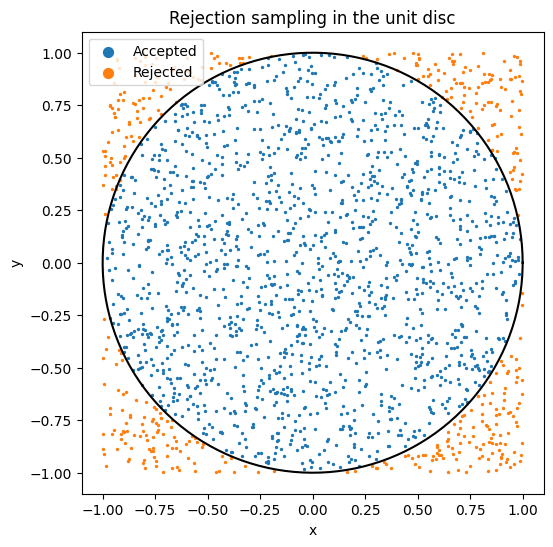

Independent area estimate from acceptance fraction: 3.118000; reference π=3.141593


In [18]:
def disc_integral(f, radius, n, return_counts=False):
    """Integrate using the known disc area and a conditional sample mean."""
    if radius <= 0 or n <= 0:
        raise ValueError('Require radius > 0 and n > 0.')
    x = np.random.uniform(-radius, radius, n)
    y = np.random.uniform(-radius, radius, n)
    inside = x**2+y**2 <= radius**2
    accepted = int(np.sum(inside))
    if accepted == 0:
        raise ValueError('No candidates entered the disc; increase n and retry.')
    estimate = np.pi*radius**2*np.mean(f(x[inside], y[inside]))
    return (estimate, n, accepted) if return_counts else estimate

def disc_area_from_hits(radius, accepted, candidates):
    if radius <= 0 or candidates <= 0 or not 0 <= accepted <= candidates:
        raise ValueError('Require a positive radius/count and valid accepted count.')
    return 4*radius**2*accepted/candidates

radius21 = 1.0
n21 = sample_count(200000)
for f, name, exact in [(lambda x, y: np.ones_like(x), 'f=1 (known-area identity)', np.pi),
                       (lambda x, y: x**2+y**2, 'f=x²+y²', np.pi/2)]:
    estimates = [disc_integral(f, radius21, n21) for _ in range(REPEATS)]
    print(f'{name}: mean={np.mean(estimates):.6f}; mean absolute error={np.mean([abs(value-exact) for value in estimates]):.6f}')

# A separate generator keeps this illustration from reseeding later experiments.
visual_generator = np.random.default_rng(42)
x_visual = visual_generator.uniform(-radius21, radius21, 2000)
y_visual = visual_generator.uniform(-radius21, radius21, 2000)
inside_visual = x_visual**2+y_visual**2 <= radius21**2
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(x_visual[inside_visual], y_visual[inside_visual], s=2, label='Accepted')
ax.scatter(x_visual[~inside_visual], y_visual[~inside_visual], s=2, label='Rejected')
theta = np.linspace(0, 2*np.pi, 300)
ax.plot(radius21*np.cos(theta), radius21*np.sin(theta), 'k-', lw=1.5)
ax.set_aspect('equal')
ax.set_title('Rejection sampling in the unit disc')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.legend(markerscale=5)
save_figure('disc-sampling.png')
area_estimate = disc_area_from_hits(radius21, int(np.sum(inside_visual)), len(inside_visual))
print(f'Independent area estimate from acceptance fraction: {area_estimate:.6f}; reference π={np.pi:.6f}')


## 18. A grid clipped to the disc — exercise 22

The original two-dimensional midpoint grid retains only nodes inside the
disc. Its estimate is $h^2\sum_{inside}f(x_i,y_j)$.

Both methods are compared using **candidate points processed per estimate**:
$m^2$ grid points or $n$ random candidates. Actual integrand evaluations are
also reported separately. Previously the grid used accepted points on the
horizontal axis while Monte Carlo used all candidates; those counters were
not comparable. Monte Carlo's curve averages absolute errors over repeated
runs, so total experimental work is larger than its per-estimate count.

Clipping the grid introduces a boundary discontinuity. No $N^{-1}$ error
guarantee for this disc computation follows from the smooth rectangle case.
Only a Monte Carlo $N^{-1/2}$ visual reference is shown.


Grid: width | candidates | evaluations | absolute error
  10 |     100 |      80 | 0.05480367
  20 |     400 |     316 | 0.01780367
  50 |    2500 |    1976 | 0.01991599
 100 |   10000 |    7860 | 0.00238415
 200 |   40000 |   31428 | 0.00120593
Monte Carlo (30 repeats): candidates | mean evaluations | mean absolute error
    100 |      79.23 | 0.07650180
    400 |     312.00 | 0.03522956
   2500 |    1966.67 | 0.01187826
  10000 |    7865.33 | 0.00708891
  40000 |   31416.00 | 0.00372042


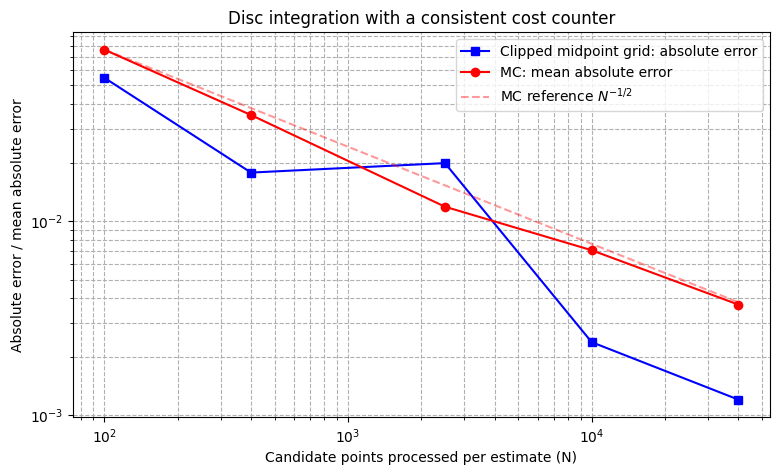

In [19]:
def disc_midpoint_rule(f, radius, m):
    """Return the estimate, candidates processed and integrand evaluations."""
    if radius <= 0 or m <= 0:
        raise ValueError('Require radius > 0 and m > 0.')
    step = 2*radius/m
    coordinates = np.linspace(-radius+step/2, radius-step/2, m)
    x, y = np.meshgrid(coordinates, coordinates)
    inside = x**2+y**2 <= radius**2
    evaluations = int(np.sum(inside))
    return step**2*np.sum(f(x[inside], y[inside])), m*m, evaluations

f22 = lambda x, y: x**2+y**2
exact22 = np.pi/2
grid_sizes = [10, 20, 50, 100, 200, 500]
grid_sizes = [m for m in grid_sizes if m*m <= MAX_SAMPLES]
rectangle_errors22, grid_candidates22, grid_evaluations22 = [], [], []
print('Grid: width | candidates | evaluations | absolute error')
for m in grid_sizes:
    estimate, candidates, evaluations = disc_midpoint_rule(f22, 1.0, m)
    error = abs(estimate-exact22)
    rectangle_errors22.append(error)
    grid_candidates22.append(candidates)
    grid_evaluations22.append(evaluations)
    print(f'{m:4d} | {candidates:7d} | {evaluations:7d} | {error:.8f}')
sizes22 = grid_candidates22.copy()
mc_errors22, mc_mean_evaluations22 = [], []
print(f'Monte Carlo ({REPEATS} repeats): candidates | mean evaluations | mean absolute error')
for n in sizes22:
    estimates = [disc_integral(f22, 1.0, n, return_counts=True) for _ in range(REPEATS)]
    error = np.mean([abs(value-exact22) for value, _, _ in estimates])
    mean_evaluations = np.mean([evaluations for _, _, evaluations in estimates])
    mc_errors22.append(error)
    mc_mean_evaluations22.append(mean_evaluations)
    print(f'{n:7d} | {mean_evaluations:10.2f} | {error:.8f}')
plt.figure(figsize=(9, 5))
plt.loglog(grid_candidates22, rectangle_errors22, 's-', color='blue', label='Clipped midpoint grid: absolute error')
plt.loglog(sizes22, mc_errors22, 'o-', color='red', label='MC: mean absolute error')
plt.loglog(sizes22, [mc_errors22[0]*(sizes22[0]/n)**0.5 for n in sizes22], '--', color='red', alpha=0.4, label=r'MC reference $N^{-1/2}$')
plt.xlabel('Candidate points processed per estimate (N)')
plt.ylabel('Absolute error / mean absolute error')
plt.title('Disc integration with a consistent cost counter')
plt.legend()
plt.grid(True, which='both', ls='--')
save_figure('disc-cost-comparison.png')


## 19. Higher-dimensional integration — exercise 23

Estimate
$$I_d=\int_{[-1,1]^d}\frac1{1+\|x\|_2^8}\,dx=2^dE[f(X)].$$
The integrand tends towards **zero**, not one, as the norm increases.
Adding a coordinate increases the squared norm for each coupled sample,
so the domain-average integrand decreases with dimension. The integral
combines this decrease with the increasing volume $2^d$; observed growth
over a few dimensions is not by itself a monotonicity proof.


In [20]:
def dimension_integral(dimension, n):
    """Uniform integral of 1/(1+||x||^8) on [-1,1]^dimension."""
    if dimension <= 0 or n <= 0:
        raise ValueError('Require a positive dimension and sample count.')
    points = np.random.uniform(-1, 1, size=(n, dimension))
    norm_power8 = np.sum(points**2, axis=1)**4
    values = 1/(1+norm_power8)
    return 2.0**dimension*np.mean(values)

reference_d1, _ = quad(lambda x: 1/(1+x**8), -1, 1)
n23 = sample_count(500000)
estimate_d1 = dimension_integral(1, n23)
print(f'd=1: quadrature={reference_d1:.6f}; MC={estimate_d1:.6f}; error={abs(estimate_d1-reference_d1):.6g}')
dimensions = [1, 2, 3, 5, 10]
dimension_results = {}
for dimension in dimensions:
    estimates = [dimension_integral(dimension, n23) for _ in range(min(20, REPEATS))]
    mean = np.mean(estimates)
    standard_deviation = np.std(estimates, ddof=1)
    dimension_results[dimension] = {'mean_integral': float(mean), 'sample_standard_deviation': float(standard_deviation), 'mean_integrand': float(mean/2**dimension)}
    print(f'd={dimension:2d}: mean integral={mean:.6f}; sample SD={standard_deviation:.6f}; mean integrand={mean/2**dimension:.6f}')


d=1: quadrature=1.849303; MC=1.849859; error=0.000555984
d= 1: mean integral=1.849281; sample SD=0.001090; mean integrand=0.924641
d= 2: mean integral=2.984400; sample SD=0.003854; mean integrand=0.746100
d= 3: mean integral=4.351356; sample SD=0.011496; mean integrand=0.543920
d= 5: mean integral=7.640671; sample SD=0.042801; mean integrand=0.238771
d=10: mean integral=22.733054; sample SD=0.227499; mean integrand=0.022200


## 20. Computational cost — exercise 24

The tensor midpoint grid uses $m^d$ points. This vectorised Monte Carlo
implementation uses $n$ points, each with $d$ coordinates, so its work and
memory are $O(nd)$ here. The evaluation count alone does not capture cost.

The standard error is $2^d\sqrt{\operatorname{Var}(f(X))/n}$: its exponent
in $n$ is $-1/2$, but its constant and the work per sample depend on dimension.
Neither a fixed $n$ nor a fixed $m$ guarantees equal accuracy across $d$.
This experiment compares one uniform sampler with one tensor grid; it does
not establish that Monte Carlo is the only viable high-dimensional method.

The grid is run only through dimension 5. Its count at dimension 10 is a
formula-based projection, not a measured run. The final table contains
estimates, not errors: only dimension 1 has an independent reference here.


d=1: MC=50000 evaluations, 0.000529s; grid=10 points, 0.000098
d=2: MC=50000 evaluations, 0.001442s; grid=100 points, 0.000107
d=3: MC=50000 evaluations, 0.002046s; grid=1000 points, 0.000121
d=5: MC=50000 evaluations, 0.003523s; grid=100000 points, 0.004560
d=10: MC=50000 evaluations, 0.005776s; grid=10000000000 points, not run


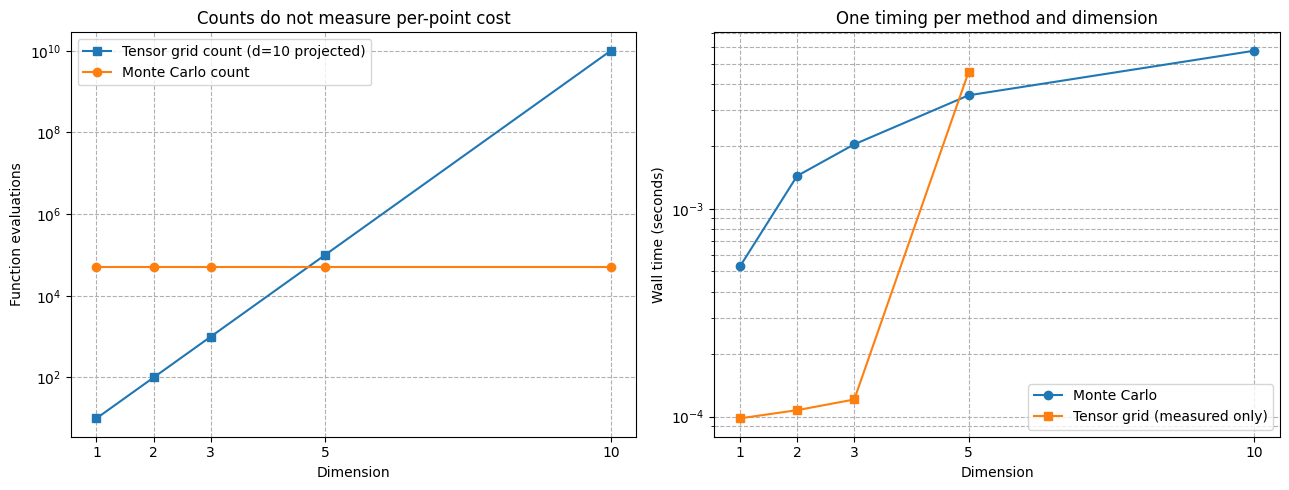

Estimates (not a table of known errors):
d=1: MC=1.850210; grid=1.856244; independent reference=1.849303
d=2: MC=2.981412; grid=3.001069; independent reference=unavailable
d=3: MC=4.356476; grid=4.381030; independent reference=unavailable
d=5: MC=7.634751; grid=7.697142; independent reference=unavailable


In [21]:
dimensions = [1, 2, 3, 5, 10]
n_mc = sample_count(100000)
m_grid = 10
mc_times, grid_times, mc_counts, grid_counts = [], [], [], []
grid_estimates = {}
for dimension in dimensions:
    start = time.perf_counter()
    dimension_integral(dimension, n_mc)
    mc_time = time.perf_counter()-start
    mc_times.append(mc_time)
    mc_counts.append(n_mc)
    total_grid = m_grid**dimension
    grid_counts.append(total_grid)
    if dimension <= 5:
        start = time.perf_counter()
        step = 2.0/m_grid
        coordinates = np.linspace(-1+step/2, 1-step/2, m_grid)
        grids = np.meshgrid(*[coordinates]*dimension, indexing='ij')
        points = np.stack([grid.ravel() for grid in grids], axis=1)
        norm_power8 = np.sum(points**2, axis=1)**4
        grid_estimates[dimension] = step**dimension*np.sum(1/(1+norm_power8))
        grid_time = time.perf_counter()-start
    else:
        grid_time = None
    grid_times.append(grid_time)
    grid_time_text = f'{grid_time:.6f}' if grid_time is not None else 'not run'
    print(f'd={dimension}: MC={n_mc} evaluations, {mc_time:.6f}s; grid={total_grid} points, {grid_time_text}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].semilogy(dimensions, grid_counts, 's-', label='Tensor grid count (d=10 projected)')
axes[0].semilogy(dimensions, mc_counts, 'o-', label='Monte Carlo count')
axes[0].set_xlabel('Dimension')
axes[0].set_ylabel('Function evaluations')
axes[0].set_title('Counts do not measure per-point cost')
measured_dimensions = [d for d, duration in zip(dimensions, grid_times) if duration is not None]
measured_times = [duration for duration in grid_times if duration is not None]
axes[1].semilogy(dimensions, mc_times, 'o-', label='Monte Carlo')
axes[1].semilogy(measured_dimensions, measured_times, 's-', label='Tensor grid (measured only)')
axes[1].set_xlabel('Dimension')
axes[1].set_ylabel('Wall time (seconds)')
axes[1].set_title('One timing per method and dimension')
for axis in axes:
    axis.legend()
    axis.grid(True, which='both', ls='--')
    axis.set_xticks(dimensions)
plt.tight_layout()
save_figure('dimension-cost.png')

print('Estimates (not a table of known errors):')
for dimension, grid_estimate in grid_estimates.items():
    estimate = dimension_integral(dimension, n_mc)
    reference_text = f'{reference_d1:.6f}' if dimension == 1 else 'unavailable'
    print(f'd={dimension}: MC={estimate:.6f}; grid={grid_estimate:.6f}; independent reference={reference_text}')

summary = {
    'prepared_on': '2026-10-17', 'seed': SEED, 'sample_cap': MAX_SAMPLES, 'repeat_cap': REPEATS,
    'python': platform.python_version(), 'numpy': np.__version__, 'scipy': scipy.__version__,
    'matplotlib': matplotlib.__version__, 'scope': 'All 24 exercises; reduced sample sizes',
    'mean_adjacent_slope_exercise8': float(np.mean(slopes)),
    'proposal_comparison': {'sample_count': n17, 'repeats': REPEATS, 'numerical_reference': reference17,
                            'uniform_mean_absolute_error': float(uniform_error17),
                            'proposal_variances': variances17, 'importance_mean_absolute_errors': [float(value) for value in proposal_errors]},
    'disc_comparison': {'counter': 'candidate points per estimate', 'candidates': grid_candidates22,
                        'grid_integrand_evaluations': grid_evaluations22,
                        'mc_mean_integrand_evaluations': mc_mean_evaluations22,
                        'grid_absolute_errors': rectangle_errors22, 'mc_mean_absolute_errors': mc_errors22},
    'dimension_results': dimension_results,
    'timings': {'dimensions': dimensions, 'mc_seconds': mc_times, 'grid_seconds': grid_times,
                'grid_dimension10': 'not run; count projected from 10**10'},
}
(RESULTS/'run-summary.json').write_text(json.dumps(summary, indent=2)+'\n', encoding='utf-8')
